# Lab Assignment 2 - Scientific Computing Lab

## Submitted by - Naman Jain, SC26M013

New positions: [0.499375 1.00875  1.493125]
New velocities: [-0.03746875  0.1245625  -0.21215625]
Half Time Step: [-0.0125  0.175  -0.1375]


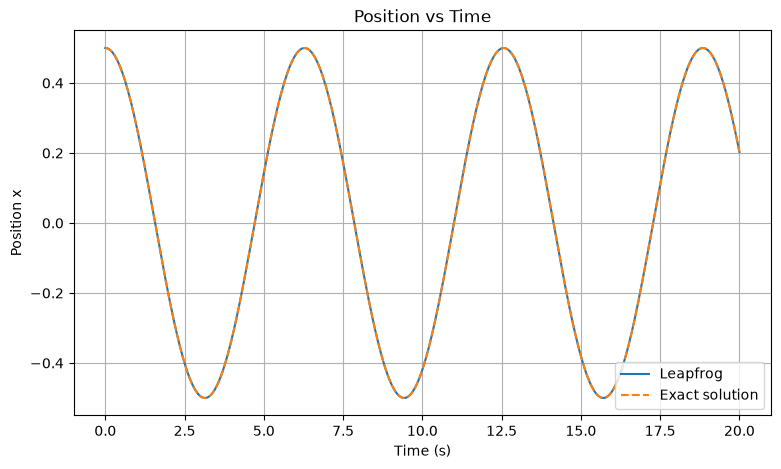

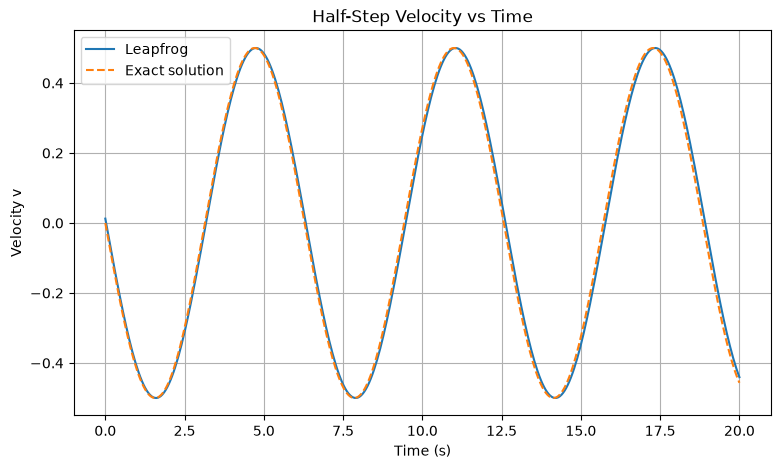

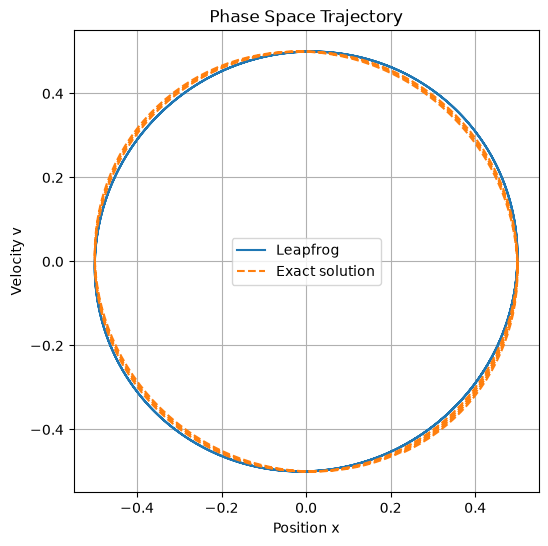

In [72]:
##Leap Frog Integration Method 
import numpy as np
import matplotlib.pyplot as plt

## Simple Leap Frog Integration for 1 iteration as asked in 1st requriement 
def leapfrog(x, v, h):
    v_half = v - 0.5 * h * x
    x_new = x + h * v_half
    v_new = v_half - h * x_new

    return x_new, v_new, v_half

x = np.array([0.5, 1.0, 1.5])
v = np.array([0.0, 0.2, -0.1])
h = 0.05

x_new, v_new, v_half = leapfrog(x, v, h)
print("New positions:", x_new)
print("New velocities:", v_new)
print("Half Time Step:", v_half)

##MAIN PART
##Comparision with Exact Solution
#Initial Conditions
omega_p = 1
h = 0.05
t = [0, 20]
n = int((t[1] - t[0]) / h)

timesteps_x = np.linspace(t[0], t[1], n+1)
timesteps_v = np.linspace(t[0], t[1], n)

x = np.zeros(n+1)
v_half = np.zeros(n)

x[0] = 0.5
v[0] = 0.0
v_minus_half = v[0] + 0.5*h*omega_p**2*x[0]

def leapfrog1(x, v, h):
    v_new = v - h * omega_p**2 * x
    x_new = x + h * v_new
    return x_new, v_new

for i in range(n):
    v_half[i] = v_minus_half
    x[i+1], v_minus_half = leapfrog1(x[i], v_minus_half, h)

# Exact solutions at corresponding times
x_exact = 0.5 * np.cos(omega_p * timesteps_x)
v_exact = -0.5 * np.sin(omega_p * timesteps_v)

# Plot position at whole time levels
plt.figure(figsize=(9, 5))
plt.plot(timesteps_x, x, label="Leapfrog")
plt.plot(timesteps_x, x_exact, "--", label="Exact solution")
plt.xlabel("Time (s)")
plt.ylabel("Position x")
plt.title("Position vs Time")
plt.legend()
plt.grid(True)
plt.show()

# Plot velocity at half time levels
plt.figure(figsize=(9, 5))
plt.plot(timesteps_v, v_half, label="Leapfrog")
plt.plot(timesteps_v, v_exact, "--", label="Exact solution")
plt.xlabel("Time (s)")
plt.ylabel("Velocity v")
plt.title("Half-Step Velocity vs Time")
plt.legend()
plt.grid(True)
plt.show()

## Phase Space Trajectory 
plt.figure(figsize=(6, 6))
plt.plot(x[0:n], v_half, label="Leapfrog")
plt.plot(x_exact[0:n], v_exact, "--", label="Exact solution")
plt.xlabel("Position x")
plt.ylabel("Velocity v")
plt.title("Phase Space Trajectory")
plt.legend()
plt.grid(True)
plt.show()